## Анализ данных о Нобелевских лауреатах

### **Контекст проекта**
В этом задании мы будем работать с датасетом о лауреатах Нобелевской премии. Ваша задача — распарсить и проанализировать эти данные, ответив на ключевые вопросы о закономерностях вручения премий, демографических характеристиках лауреатов и исторических тенденциях.

### **Этап 1: Подготовка данных**

**Задача:** На этом этапе вам надо собрать структурированный список словарей с информацией о лауреатах и призах. Приведем начало нужного нам датасета.

``` {code:python}
[{'id': '745',
  'name': 'A. Michael Spence',
  'gender': 'male',
  'birth_year': 1943,
  'country_birth': 'USA',
  'country_now': 'USA',
  'prizes_relevant': [{'prize_amount': 10000000,
    'prize_amount_adjusted': 15547541,
    'award_year': 2001,
    'category_en': 'Economic Sciences',
    'prize_status': 'received'}],
  'type_': 'person'},
 {'id': '102',
  'name': 'Aage N. Bohr',
  'gender': 'male',
  'birth_year': 1922,
  'country_birth': 'Denmark',
  'country_now': 'Denmark',
  'prizes_relevant': [{'prize_amount': 630000,
    'prize_amount_adjusted': 4304697,
    'award_year': 1975,
    'category_en': 'Physics',
    'prize_status': 'received'}],
  'type_': 'person'}]
  ```

Поскольку информация о лауреатах-людях и лауреатах-организациях структурирована по-разному, а также из-за того, что часть полей в json могут отсутстввовать, необходимо реализовать функции для процессинга словарей, которые будут достаточно обобщаемыми для обоих типов данных.

**Что нужно сделать:**

На входе информация о конкретном лауреате представляет из себя кучу вложенных друг в друга словарей. Из этой структуры нам надо получить плоский словарь вида {atribute: value}, где atribute --- это один из небольшого множества интересных нам атрибутов. При этом в исходном файле 
1. пути к атрибутам могут иметь разную длину
2. атрибуты могут отсутствовать
3. атрибуты могут нуждаться в дополнительной обработке (например, поле id в исходных словарях записано как строка.)

Поскольку наивная реализация такого обработчика оказывается довольно громоздкой, вам нужно создать файл json_dict_processing.py, в котором реализован высокоуровневый функционал для решения задачи "обработать вложенный json-словарь"

Главное требование к интерфейсу: 
по (вложенному) словарю о лауреате и конфигу (см ниже) надо получить плоский словарь вида {atribute: value}.

Достичь этого можно, например, таким набором функций

* `extract_nested_value(obj, keys)` - извлекает значение из вложенных структур данных по цепочке ключей

* `process_dictionary_with_config(dictionary, config)` - обрабатывает один словарь согласно словару-конфигу (формат конфига см ниже.)

* `process_list_of_dicts_with_config(list_of_dicts, config)` - обрабатывает список словарей, эта функция нужна чтобы обработать список призов.

* `create_processor(config, list_processor=False)` - создает готовый процессор с предзагруженной конфигурацией. В случае, если list_processor == True, внутрь процессора подается process_list_of_dicts_with_config, иначе process_dictionary_with_config.

**Замечание насчет последней функции.**

Планируемое применение этой функции примерно такое:
`laureate_processor = create_processor(PERSON_CONFIG, list_processor=False)`

То есть, create_processor возвращает функцию, которая реализует функционал process_dictionary_with_config но с уже заполненным конфигом. Это повышает читаемость кода и снижает риск перепутать конфиги из-за дублирования кода.


Помимо этого нужно создать файлы-конфиги для данных по призам, лауреатам-людям, и лауреатам-организациям.

КОНФИГ для функций process_dictionary_with_config и process_list_of_dicts_with_config имеет следующий вид
```python
  {'атрибут_который_берем_сырым': ['путь', 'к', 'данным'],  # или
  'атрибут_который_нужно_обработать': (['путь', 'к', 'данным'], функция_обработки)}
  ```
В случае, если атрибут можно взять в итоговый датасет сырым, в values() словаря-конфига будет список path_list.
Если же атрибут еще надо обработать, для него в поле config[attribute] будет tuple вида (path_list, function).

Примеры атрибутов, которые можно взять сырыми: имя, размер приза. Примеры атрибутов, которые нужно обработать: год вручения приза (в сырых данных есть только полная дата, записанная как строка)

После того, как будет создан core.py, создайте конфиги laureates_configs.py и prizes_configs.py

Постарайтесь провалидировать код с помощью assert-ов, вызываемых в ноутбуке или в .py-файлах.

пример использования: 

assert 1 == True

**Валидация**

В вашем случае assert должен взять простой словарик с одним вложенным полем и какой-нибудь конфиг-файл.
Также убедитесь, что при обработке данных собственно по лауреатам в них нет странностей (смотрите ниже) 

**Атрибуты для ПРИЗА (CONFIG_PRIZE, prizes_configs.py)**

- `prize_amount` - сумма приза → `prizeAmount`
- `prize_amount_adjusted` - скорректированная сумма приза → `prizeAmountAdjusted`
- `award_year` - год вручения приза (преобразуется в целое число) → `awardYear`
- `category_en` - категория на английском → `category.en`
- `prize_status` - статус приза → `prizeStatus`

**Атрибуты для ЧЕЛОВЕКА-ЛАУРЕАТА (CONFIG_PERSON, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - имя лауреата → `knownName.en`
- `gender` - пол → `gender`
- `birth_year` - год рождения (извлекается из даты) → `birth.date`
- `country_birth` - страна рождения → `birth.place.country.en`
- `country_now` - текущая страна → `birth.place.countryNow.en`
- `prizes_relevant` - список призов лауреата → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Атрибуты для ОРГАНИЗАЦИИ-ЛАУРЕАТА (CONFIG_ORG, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - название организации → `orgName.en`
- `founded_year` - год основания (извлекается из даты) → `founded.date`
- `country_founded` - страна основания → `founded.place.country.en`
- `country_now` - текущая страна → `founded.place.countryNow.en`
- `prizes_relevant` - список призов организации → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Вспомогательные функции:**

- `process_year(year_string)` - извлекает год из строки даты (формат "YYYY-MM-DD"). Функция находится в файле laureates_configs.py
- `prize_processor()` - создает процессор для обработки списков призов. Функция находится в файле prizes_configs.py
- `person_processor()` - создает процессор для данных о людях-лауреатах. Функция находится в файле laureates_configs.py
- `org_processor()` - создает процессор для данных об организациях-лауреатах. Функция находится в файле laureates_configs.py

In [1]:
import requests
URL_LAUREATES = f'https://api.nobelprize.org/2.1/laureates?limit=1200'

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36',
    'Accept': 'application/json'
}

laureates_response = requests.get(URL_LAUREATES, headers=headers)
laureates = laureates_response.json()

In [2]:
from process.laureates_configs import process_orgs, process_persons

def get_laureate_data(laureate):
    """
    Определите тип лауреата and соотв образом обработайте данных.
    
    Args:
        laureate: Dictionary with laureate data
        
    Returns:
        Processed laureate data with added 'type_' field ('person' or 'org')
        
    Determines type by:
    - 'knownName' key → person (uses process_persons)
    - 'orgName' key → org (uses process_orgs)
    """
    if 'knownName' in laureate:
        laureate_data = process_persons(laureate)
        laureate_data['type_'] = 'person'
    elif 'orgName' in laureate:
        laureate_data = process_orgs(laureate)
        laureate_data['type_'] = 'org'
    else:
        raise ValueError('Лауреат должен быть либо человеком, либо организацией')
    return laureate_data
    

laureates_data = []

for laureate in laureates['laureates']:
    laureates_data.append(get_laureate_data(laureate))



### **Этап 2: EDA лауреатов**

EDA или Exploratory Data Analysis - первый шаг при работе с любыми данными.

Чтобы начать работать с этой секцией, проведите проведите чисто технический анализ собранных данных.

1. Сколько всего записей?
2. Все ли значения полей заполнены?
3. Если нет, сколько пропусков в каждом из полей? Выведите ответ на этот вопрос в формате `{'field_name': missing_values}`. А какая доля пропусков?
5. Каковы максимальные и минимальные значения поля id и каким годам награждения они соответствуют? Есть ли записи с повторяющимися id? Есть ли пары айди, которые в отсортированном массиве айдишников различаются более, чем на один? 

При реализации ответов на эти вопросы, пользуйтесь теми же принципами, что описаны выше. Можете начать с плохого хакерского кода, однако в таком случае в маркдауне пропишите, как будете его обобщать и разносить по функциям и модулям. (об этом ниже)

В основном EDA пользуйтесь аккуратным кодом, разбитым на функции и файлы.

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter

from dataset_tools.aggregations import agg
from dataset_tools.dataset_helpers import group_by, where, apply, sort_values
from dataset_tools.attribute_manager import get_column, add_column, \
    delete_columns, concat, flat, get_columns

In [4]:
laureates_person = where(laureates_data, lambda x: x['type_'] == 'person')
laureates_org = where(laureates_data, lambda x: x['type_'] == 'org')

In [5]:
def tech_analysis(data):
    total_count = len(data)
    print(f'Всего записей: {total_count}')

    print('Пропуски:')
    missing_values_count = agg(data, 'none_count')
    print(missing_values_count)

    print('Доля пропусков:')
    print({k: v / total_count for k, v in missing_values_count.items()})

    min_id = agg(data, {'id': 'min'})['id_min']
    max_id = agg(data, {'id': 'max'})['id_max']
    print(f'Минимальное id: {min_id}, максимальное id: {max_id}')

    laureates_with_min_id = where(data, lambda x: x['id'] == min_id)
    laureates_with_max_id = where(data, lambda x: x['id'] == max_id)

    print('Года с минимальным id: ',
          get_column(
              flat(get_column(laureates_with_min_id, 'prizes_relevant')),
              'award_year'
          )
    )
    print('Года с максимальным id: ',
          get_column(
              flat(get_column(laureates_with_max_id, 'prizes_relevant')),
              'award_year'
          )
    )

    print(f'Уникальных id: {agg(data, {'id': 'count'})['id_count']} из {total_count}')
    print('Повторяющиеся id: ', where(agg(group_by(data, ['id']), {'id': 'count'}), lambda x: x['id_count'] > 1))

In [6]:
print('Технический анализ данных о лауреатах-людях')
tech_analysis(laureates_person)

Технический анализ данных о лауреатах-людях
Всего записей: 1000
Пропуски:
{'id_none_count': 0, 'name_none_count': 0, 'gender_none_count': 0, 'birth_year_none_count': 0, 'country_birth_none_count': 3, 'country_now_none_count': 3, 'prizes_relevant_none_count': 0, 'type__none_count': 0}
Доля пропусков:
{'id_none_count': 0.0, 'name_none_count': 0.0, 'gender_none_count': 0.0, 'birth_year_none_count': 0.0, 'country_birth_none_count': 0.003, 'country_now_none_count': 0.003, 'prizes_relevant_none_count': 0.0, 'type__none_count': 0.0}
Минимальное id: 1, максимальное id: 1070
Года с минимальным id:  [1901]
Года с максимальным id:  [2026]
Уникальных id: 1000 из 1000
Повторяющиеся id:  []


In [7]:
print('Технический анализ данных о лауреатах-организациях')
tech_analysis(laureates_org)

Технический анализ данных о лауреатах-организациях
Всего записей: 28
Пропуски:
{'id_none_count': 0, 'name_none_count': 0, 'founded_year_none_count': 1, 'country_founded_none_count': 4, 'country_now_none_count': 4, 'prizes_relevant_none_count': 0, 'type__none_count': 0}
Доля пропусков:
{'id_none_count': 0.0, 'name_none_count': 0.0, 'founded_year_none_count': 0.03571428571428571, 'country_founded_none_count': 0.14285714285714285, 'country_now_none_count': 0.14285714285714285, 'prizes_relevant_none_count': 0.0, 'type__none_count': 0.0}
Минимальное id: 467, максимальное id: 1043
Года с минимальным id:  [1904]
Года с максимальным id:  [2024]
Уникальных id: 28 из 28
Повторяющиеся id:  []



Поскольку это курс по Python, а не по статистике или визуализации данных, мы не задаем жесткие рамки того, что вы должны проанализировать.
Однако это отличная возможность представить себя в роли разработчика базы данных или, например, библиотеки pandas.

В коде нужно соблюдать следующие правила:

1. должны быть реализованы  несколько способов работы с данными (среднее/медианное/максимальное значение метрики, количество примеров, вывод топ-N объектов по значению метрики).
2. анализ выбранных вами тем должен включать в себя анализ метрик в тотале, по категориям и в динамике по годам или десятилетиям.
3. проанализировать стоит 2-3 темы. Вы можете использовать темы ниже или взять свои.
2. вывод ноутбука должен быть понятен обывателю. Это может быть визуализация в matplotlib/seaborn. Сопровождайте вывод markdown-ячейками с вашими  мыслями, пояснениями и инсайтами, которые удалось извлечь.
3. Нельзя использовать pandas и numpy, но можно вдохновляться их интерфейсом и функционалом при дизайне ваших функций.


Из пункта 2 следует, что вам придется работать не только с атрибутами лауреатов, но и самих призов.
Информацию о призах нужно доставать и записывать как атрибут уже лауреата. Функции, работающие с призами (например, факт того, что лауреат отказался от какого-то из призов) можно реализовать в ноутбуке, но если вы создаете более общие вспомогательные функции, выносите их в отдельные модули.

Мы рекомендуем следующую структуру кода:

* `dataset_tools/dataset_helpers.py` в котором реализованы фильтрация списка словарей (плоских) по условиям (аналог sql-ного where), а также аналог sql-ного групбая. А также функция для применения агрегаций к списку словарей
* `dataset_tools/aggregations.py` в котором реализованы функции расчета среднего/медианы/других эвристик и мб вывод топ n-значений по какой-то метрике.
* `dataset_tools/attribute_manager.py` в котором реализован переиспользуемый интерфейс для добавления (и мб удаления) полей.

Замечание насчет group-by. 

На игрушесном примере она может работать примерно так:
```
    Входные данные: [
        {'name': 'Alice', 'country': 'USA', 'age': 25},
        {'name': 'Bob', 'country': 'UK', 'age': 30},
        {'name': 'Charlie', 'country': 'USA', 'age': 25}
    ]
    
    group_by_attributes(data, ['country', 'age']) → {
        ('USA', 25): [
            {'name': 'Alice', 'country': 'USA', 'age': 25},
            {'name': 'Charlie', 'country': 'USA', 'age': 25}
        ],
        ('UK', 30): [
            {'name': 'Bob', 'country': 'UK', 'age': 30}
        ]
    }
```

Замечание насчет agregations.py
1. Агрегации соответственно должны применяться к спискам вида [
    {'name': 'Alice', 'country': 'USA', 'age': 25},
    {'name': 'Charlie', 'country': 'USA', 'age': 25}
]
2. Пользуйтесь модулем statistics из стандартной библиотеки питона.


Эта структура одна из возможных для организации вашего кода, главное, чтобы эти достаточно общие функции блыи переиспользованы

----------

## Возраст при награждении

- Рассчитать средний возраст лауреатов на момент получения **первого** приза. Рассмотрите только лауреатов-людей.
- Исследуйте, как средний возраст получения первого приза различается по категориям
- Различаются ли средний и медианный возрасты?

In [8]:
from pprint import pprint

In [9]:
def sort_laureate_prizes_by_year(laureate: dict) -> list[dict]:
    if 'prizes_relevant' not in laureate:
        pprint(laureate['type_'])
    return sort_values(laureate['prizes_relevant'], columns=['award_year'])

In [10]:
first_prizes = apply(
    laureates_person,
    lambda laureate: sort_laureate_prizes_by_year(laureate)[0]
)

persons_with_first_prizes = delete_columns(
    concat(laureates_person, first_prizes, axis=1),
    ['prizes_relevant', 'name', 'gender', 'id', 'type_']
)

persons_with_first_prizes = add_column(
    persons_with_first_prizes,
    column='age',
    values=apply(
        persons_with_first_prizes,
        lambda p: p['award_year'] - p['birth_year']
    ),
)

In [11]:
avg_age = agg(persons_with_first_prizes, {'age': 'mean'})['age_mean']
print(f'Средний возраст на момент получения первой награды: {avg_age:.2f}')

median_age = agg(persons_with_first_prizes, {'age': 'median'})['age_median']
print(f'Медианный возраст на момент получения первой награды: {median_age:.2f}')

Средний возраст на момент получения первой награды: 60.61
Медианный возраст на момент получения первой награды: 61.00


In [12]:
avg_median_age_category = get_columns(agg(
    group_by(persons_with_first_prizes, columns=['category_en']),
    {'age': ['mean', 'median']}
))

category_count = len(avg_median_age_category['category_en'])

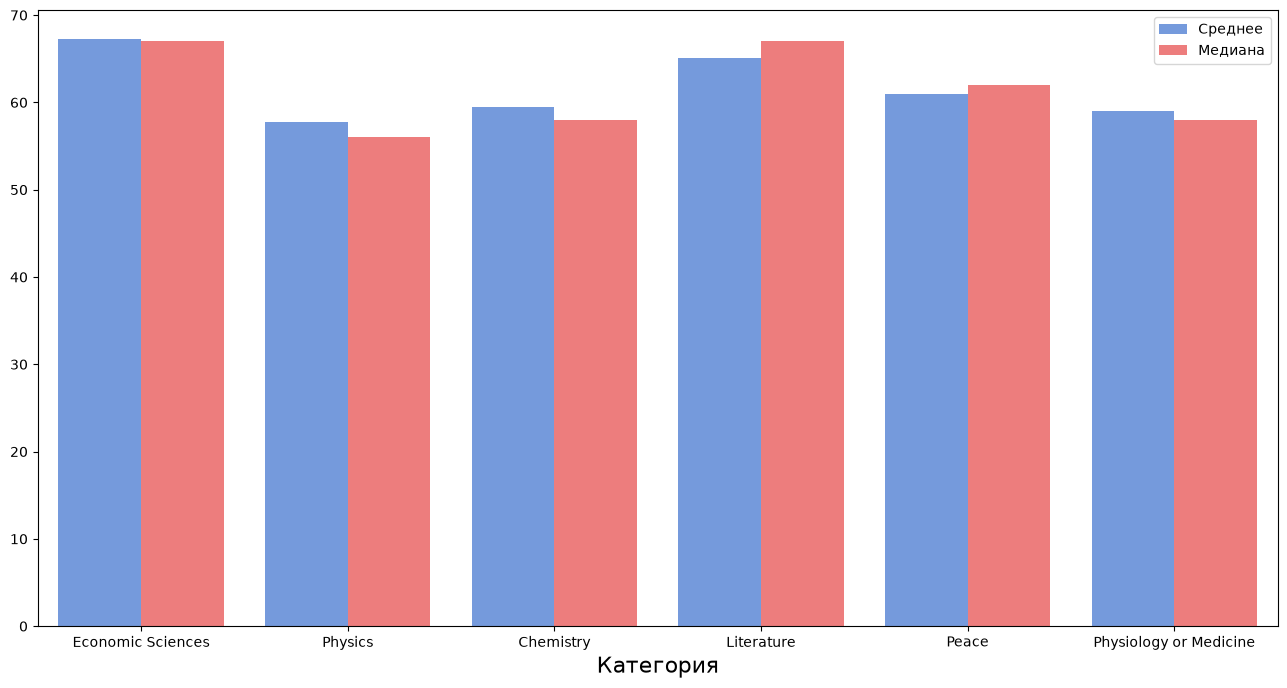

In [13]:
plt.figure(figsize=(16, 8))
sns.barplot(
    x=avg_median_age_category['category_en'] * 2,
    y=avg_median_age_category['age_mean'] + avg_median_age_category['age_median'],
    hue=['Среднее'] * category_count + ['Медиана'] * category_count,
    palette={'Среднее': '#6495ED',
             'Медиана': '#FF6B6B'}
)
plt.xlabel('Категория', fontsize=16)
plt.show()

## Многократные лауреаты
- Найдите лауреатов, получившие больше одного приза. Кто получил больше 2 раз?
- Совпадает ли категория второго приза с первой?
- Сколько в среднем времени прошло между получением первой и второй премии?

In [14]:
org_columns = set(get_columns(laureates_org))
person_columns = set(get_columns(laureates_person))
all_laureates = concat(
    delete_columns(
        laureates_person,
        columns=list(person_columns - org_columns)
    ),
    delete_columns(
        laureates_org,
        columns=list(org_columns - person_columns)
    ),
    axis=0
)

count_prizes = apply(
    all_laureates,
    lambda x: len(x['prizes_relevant'])
)

laureates_count_prizes = add_column(all_laureates, column='prize_cnt', values=count_prizes)

multiple_laureates = where(laureates_count_prizes, lambda x: x['prize_cnt'] > 1)
print(len(multiple_laureates))
pprint(multiple_laureates)

7
[{'country_now': 'United Kingdom',
  'id': 222,
  'name': 'Frederick Sanger',
  'prize_cnt': 2,
  'prizes_relevant': [{'award_year': 1958,
                       'category_en': 'Chemistry',
                       'prize_amount': 214559,
                       'prize_amount_adjusted': 3346838,
                       'prize_status': 'received'},
                      {'award_year': 1980,
                       'category_en': 'Chemistry',
                       'prize_amount': 880000,
                       'prize_amount_adjusted': 3654081,
                       'prize_status': 'received'}],
  'type_': 'person'},
 {'country_now': 'USA',
  'id': 66,
  'name': 'John Bardeen',
  'prize_cnt': 2,
  'prizes_relevant': [{'award_year': 1956,
                       'category_en': 'Physics',
                       'prize_amount': 200123,
                       'prize_amount_adjusted': 3413609,
                       'prize_status': 'received'},
                      {'award_year': 1972,
        

In [15]:
three_time_laureates = where(multiple_laureates, lambda x: x['prize_cnt'] > 2)
print(len(three_time_laureates))
pprint(three_time_laureates)

1
[{'country_now': 'Switzerland',
  'id': 482,
  'name': 'International Committee of the Red Cross',
  'prize_cnt': 3,
  'prizes_relevant': [{'award_year': 1917,
                       'category_en': 'Peace',
                       'prize_amount': 133823,
                       'prize_amount_adjusted': 4957724,
                       'prize_status': 'received'},
                      {'award_year': 1944,
                       'category_en': 'Peace',
                       'prize_amount': 121841,
                       'prize_amount_adjusted': 3174561,
                       'prize_status': 'received'},
                      {'award_year': 1963,
                       'category_en': 'Peace',
                       'prize_amount': 265000,
                       'prize_amount_adjusted': 3590371,
                       'prize_status': 'received'}],
  'type_': 'org'}]


In [17]:
multiple_laureates = add_column(
    multiple_laureates,
    column='is_equal',
    values=apply(
        multiple_laureates,
        lambda l: sort_laureate_prizes_by_year(l)[1]['category_en'] \
            == sort_laureate_prizes_by_year(l)[0]['category_en']
    )
)

multiple_laureates = add_column(
    multiple_laureates,
    column='interval',
    values=apply(
        multiple_laureates,
        lambda l: sort_laureate_prizes_by_year(l)[1]['award_year'] \
            - sort_laureate_prizes_by_year(l)[0]['award_year']
    )
)

In [18]:
delete_columns(multiple_laureates, ['prizes_relevant'])

[{'id': 222,
  'name': 'Frederick Sanger',
  'country_now': 'United Kingdom',
  'type_': 'person',
  'prize_cnt': 2,
  'is_equal': True,
  'interval': 22},
 {'id': 66,
  'name': 'John Bardeen',
  'country_now': 'USA',
  'type_': 'person',
  'prize_cnt': 2,
  'is_equal': True,
  'interval': 16},
 {'id': 743,
  'name': 'K. Barry Sharpless',
  'country_now': 'USA',
  'type_': 'person',
  'prize_cnt': 2,
  'is_equal': True,
  'interval': 21},
 {'id': 217,
  'name': 'Linus Pauling',
  'country_now': 'USA',
  'type_': 'person',
  'prize_cnt': 2,
  'is_equal': False,
  'interval': 8},
 {'id': 6,
  'name': 'Marie Curie',
  'country_now': 'Poland',
  'type_': 'person',
  'prize_cnt': 2,
  'is_equal': False,
  'interval': 8},
 {'id': 482,
  'name': 'International Committee of the Red Cross',
  'country_now': 'Switzerland',
  'type_': 'org',
  'prize_cnt': 3,
  'is_equal': True,
  'interval': 27},
 {'id': 515,
  'name': 'Office of the United Nations High Commissioner for Refugees',
  'country_now

In [19]:
agg(multiple_laureates, {'interval': ['mean', 'median'], 'is_equal': 'sum'})

{'interval_mean': 18.428571428571427, 'interval_median': 21, 'is_equal_sum': 5}

## Отказы от премий
- Определите, в каких категориях чаще отказывались от премий?
- Есть ли отказы среди организаций?

In [21]:
Counter(get_column(flat(get_column(all_laureates, 'prizes_relevant')), 'prize_status'))

Counter({'received': 1033, 'declined': 2, 'restricted': 1})

In [23]:
declined_laureates = where(
    all_laureates,
    lambda l: 'declined' in get_column(l['prizes_relevant'], 'prize_status') \
        or 'restricted' in get_column(l['prizes_relevant'], 'prize_status')
)

In [24]:
declined_prizes = flat(get_column(declined_laureates, 'prizes_relevant'))

Counter(get_column(declined_prizes, 'category_en'))

Counter({'Literature': 2, 'Peace': 1})

In [25]:
Counter(get_column(declined_laureates, 'type_'))

Counter({'person': 3})